# CRISP-NET Fase 4: Avaliação de Modelos Teóricos Sintéticos de Rede
### Análise Histórica de Redes da Ordem Terceira do Carmo de Vila Rica (1746–1803)

**Objetivo**: Testar e confrontar modelos teóricos de redes complexas contra a rede empírica baseline da OTCVR para determinar qual modelo melhor descreve os mecanismos geradores da governança colonial mineira:
- **Baseline Empírica**: Grafo não-direcionado derivado do livro de entradas e atas da Mesa Diretora.
- **Modelo Watts-Strogatz (WS)**: Mundo Pequeno (*Small-World*).
- **Modelo Barabási-Albert (BA)**: Livre de Escala (*Scale-Free* / Ligação Preferencial).
- **Modelo Holme-Kim (BA-WS)**: *Power-Law Cluster Graph* (Ligação Preferencial + Fechamento de Tríades).


In [1]:
# 1. IMPORTAÇÕES E CONFIGURAÇÃO
import os
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Função de localização robusta do arquivo de arestas
def localizar_csv(nome_arquivo):
    candidatos = [
        nome_arquivo,
        os.path.join("notebooks", nome_arquivo),
        os.path.join("..", "notebooks", nome_arquivo),
        os.path.join("artigo", nome_arquivo),
        os.path.join("..", "artigo", nome_arquivo),
        os.path.join(os.path.dirname(__file__) if '__file__' in globals() else '.', nome_arquivo)
    ]
    for p in candidatos:
        if os.path.exists(p):
            return os.path.abspath(p)
    return nome_arquivo

PATH_EDGES_CSV = localizar_csv("edges.csv")
print(f"Carregando arestas de: {PATH_EDGES_CSV}")


Carregando arestas de: D:\web\otcvr\otcvr\notebooks\edges.csv


In [2]:
# 2. CARREGAMENTO E MÉTRICAS DA REDE BASELINE EMPÍRICA
edges_df = pd.read_csv(PATH_EDGES_CSV)

# Suporte flexível a nomes de colunas
src_col = 'Origem (Source)' if 'Origem (Source)' in edges_df.columns else 'source'
tgt_col = 'Destino (Target)' if 'Destino (Target)' in edges_df.columns else 'target'
camada_col = 'Camada' if 'Camada' in edges_df.columns else 'camada'
ano_col = 'Ano' if 'Ano' in edges_df.columns else 'ano'

edges_df = edges_df.dropna(subset=[src_col, tgt_col]).copy()
edges_df['u'] = edges_df[[src_col, tgt_col]].min(axis=1)
edges_df['v'] = edges_df[[src_col, tgt_col]].max(axis=1)

df_grouped = edges_df.groupby(['u', 'v']).size().reset_index(name='Peso')
G = nx.from_pandas_edgelist(df_grouped, source='u', target='v')

N = G.number_of_nodes()
L = G.number_of_edges()
avg_k = 2 * L / N
dens = nx.density(G)
C_base = nx.average_clustering(G)

components = sorted(nx.connected_components(G), key=len, reverse=True)
G_gc = G.subgraph(components[0]).copy()
d_base = nx.average_shortest_path_length(G_gc)
diam_base = nx.diameter(G_gc)

k_ws = int(round(avg_k))  # 21
m_ba = int(round(avg_k / 2))  # 10

print('=' * 60)
print('ETAPA 1: MÉTRICAS DA REDE BASELINE EMPÍRICA (ATUALIZADA)')
print('=' * 60)
print(f'Nós Ativos (N): {N} | Arestas Simples (L): {L}')
print(f'Grau Médio <k>: {avg_k:.2f} | Densidade: {dens:.4f}')
print(f'Agrupamento Médio (C): {C_base:.4f}')
print(f'Distância Média <d>: {d_base:.4f} (Calculado no Comp. Gigante)')
print(f'Diâmetro do Comp. Gigante: {diam_base}')
print(f'\nParâmetros travados para modelos sintéticos: N={N}, k_ws={k_ws}, m_ba={m_ba}')


ETAPA 1: MÉTRICAS DA REDE BASELINE EMPÍRICA (ATUALIZADA)
Nós Ativos (N): 1321 | Arestas Simples (L): 13602
Grau Médio <k>: 20.59 | Densidade: 0.0156
Agrupamento Médio (C): 0.4424
Distância Média <d>: 2.8035 (Calculado no Comp. Gigante)
Diâmetro do Comp. Gigante: 8

Parâmetros travados para modelos sintéticos: N=1321, k_ws=21, m_ba=10


In [3]:
# 3. GERAÇÃO E AVALIAÇÃO DOS MODELOS SINTÉTICOS COM 5 REPLICAÇÕES
models = {
    f"WS (Mundo Pequeno) [k={k_ws}, p=0.01]": lambda: nx.watts_strogatz_graph(N, k_ws, p=0.01),
    f"BA (Livre de Escala) [m={m_ba}]": lambda: nx.barabasi_albert_graph(N, m_ba),
    f"BA-WS (Holme-Kim) [m={m_ba}, p=0.9]": lambda: nx.powerlaw_cluster_graph(N, m_ba, p=0.9),
}

G_ws_rep, G_ba_rep, G_baws_rep = None, None, None
rep_stats = {}

print('=' * 60)
print('ETAPA 2: AVALIAÇÃO DE MODELOS SINTÉTICOS E 5 REPLICAÇÕES')
print('=' * 60)

for name, func in models.items():
    Cs, ds = [], []
    print(f'\nRodando 5 replicações para: {name}')
    for i in range(5):
        random.seed(42 + i)
        np.random.seed(42 + i)
        g = func()
        gc = g.subgraph(sorted(nx.connected_components(g), key=len, reverse=True)[0])
        c = nx.average_clustering(g)
        d = nx.average_shortest_path_length(gc)
        Cs.append(c)
        ds.append(d)
        print(f'  Rep {i+1}: C={c:.4f}, d={d:.4f}')
        if i == 0:
            if 'WS (Mundo' in name: G_ws_rep = g
            elif 'BA-WS' in name: G_baws_rep = g
            else: G_ba_rep = g
    rep_stats[name] = {'C_mean': np.mean(Cs), 'C_std': np.std(Cs), 'd_mean': np.mean(ds), 'd_std': np.std(ds)}
    print(f'  [MÉDIA] -> C: {np.mean(Cs):.4f} (±{np.std(Cs):.4f}) | d: {np.mean(ds):.4f} (±{np.std(ds):.4f})')


ETAPA 2: AVALIAÇÃO DE MODELOS SINTÉTICOS E 5 REPLICAÇÕES

Rodando 5 replicações para: WS (Mundo Pequeno) [k=21, p=0.01]
  Rep 1: C=0.6919, d=5.3690
  Rep 2: C=0.6934, d=5.4602
  Rep 3: C=0.6856, d=5.0137
  Rep 4: C=0.6885, d=5.1836
  Rep 5: C=0.6888, d=5.1380
  [MÉDIA] -> C: 0.6897 (±0.0027) | d: 5.2329 (±0.1610)

Rodando 5 replicações para: BA (Livre de Escala) [m=10]
  Rep 1: C=0.0510, d=2.6198
  Rep 2: C=0.0488, d=2.6307
  Rep 3: C=0.0497, d=2.6266
  Rep 4: C=0.0471, d=2.6329
  Rep 5: C=0.0516, d=2.6243
  [MÉDIA] -> C: 0.0497 (±0.0016) | d: 2.6268 (±0.0047)

Rodando 5 replicações para: BA-WS (Holme-Kim) [m=10, p=0.9]
  Rep 1: C=0.2252, d=2.6792
  Rep 2: C=0.2233, d=2.6872
  Rep 3: C=0.2321, d=2.6938
  Rep 4: C=0.2297, d=2.6921
  Rep 5: C=0.2257, d=2.6481
  [MÉDIA] -> C: 0.2272 (±0.0032) | d: 2.6801 (±0.0168)


In [4]:
# 4. ANÁLISE DE SENSIBILIDADE DE PARÂMETROS
print('=' * 60)
print('ETAPA 3: INFLUÊNCIA DOS PARÂMETROS (SENSIBILIDADE)')
print('=' * 60)

print("-- Variação WS (Probabilidade de religação p) --")
for p in [0.01, 0.1, 0.5]:
    g = nx.watts_strogatz_graph(N, k_ws, p=p, seed=42)
    gc = g.subgraph(sorted(nx.connected_components(g), key=len, reverse=True)[0])
    print(f" WS [p={p:<4}]: C={nx.average_clustering(g):.4f} | d={nx.average_shortest_path_length(gc):.4f}")

print("\n-- Variação BA (Conexões m por novo nó) --")
for m in [5, 10, 20]:
    g = nx.barabasi_albert_graph(N, m, seed=42)
    print(f" BA [m={m:<2}]: C={nx.average_clustering(g):.4f} | d={nx.average_shortest_path_length(g):.4f}")

print("\n-- Variação BA-WS (Probabilidade p de formar triângulo) --")
for p in [0.1, 0.5, 0.9, 1.0]:
    g = nx.powerlaw_cluster_graph(N, m_ba, p=p, seed=42)
    print(f" BA-WS [p={p:<3}]: C={nx.average_clustering(g):.4f} | d={nx.average_shortest_path_length(g):.4f}")


ETAPA 3: INFLUÊNCIA DOS PARÂMETROS (SENSIBILIDADE)
-- Variação WS (Probabilidade de religação p) --
 WS [p=0.01]: C=0.6919 | d=5.3690
 WS [p=0.1 ]: C=0.5196 | d=3.3604
 WS [p=0.5 ]: C=0.0965 | d=2.7738

-- Variação BA (Conexões m por novo nó) --
 BA [m=5 ]: C=0.0393 | d=3.0438
 BA [m=10]: C=0.0510 | d=2.6198
 BA [m=20]: C=0.0793 | d=2.2456

-- Variação BA-WS (Probabilidade p de formar triângulo) --
 BA-WS [p=0.1]: C=0.0700 | d=2.6158
 BA-WS [p=0.5]: C=0.1432 | d=2.5684
 BA-WS [p=0.9]: C=0.2252 | d=2.6792
 BA-WS [p=1.0]: C=0.3598 | d=2.9269


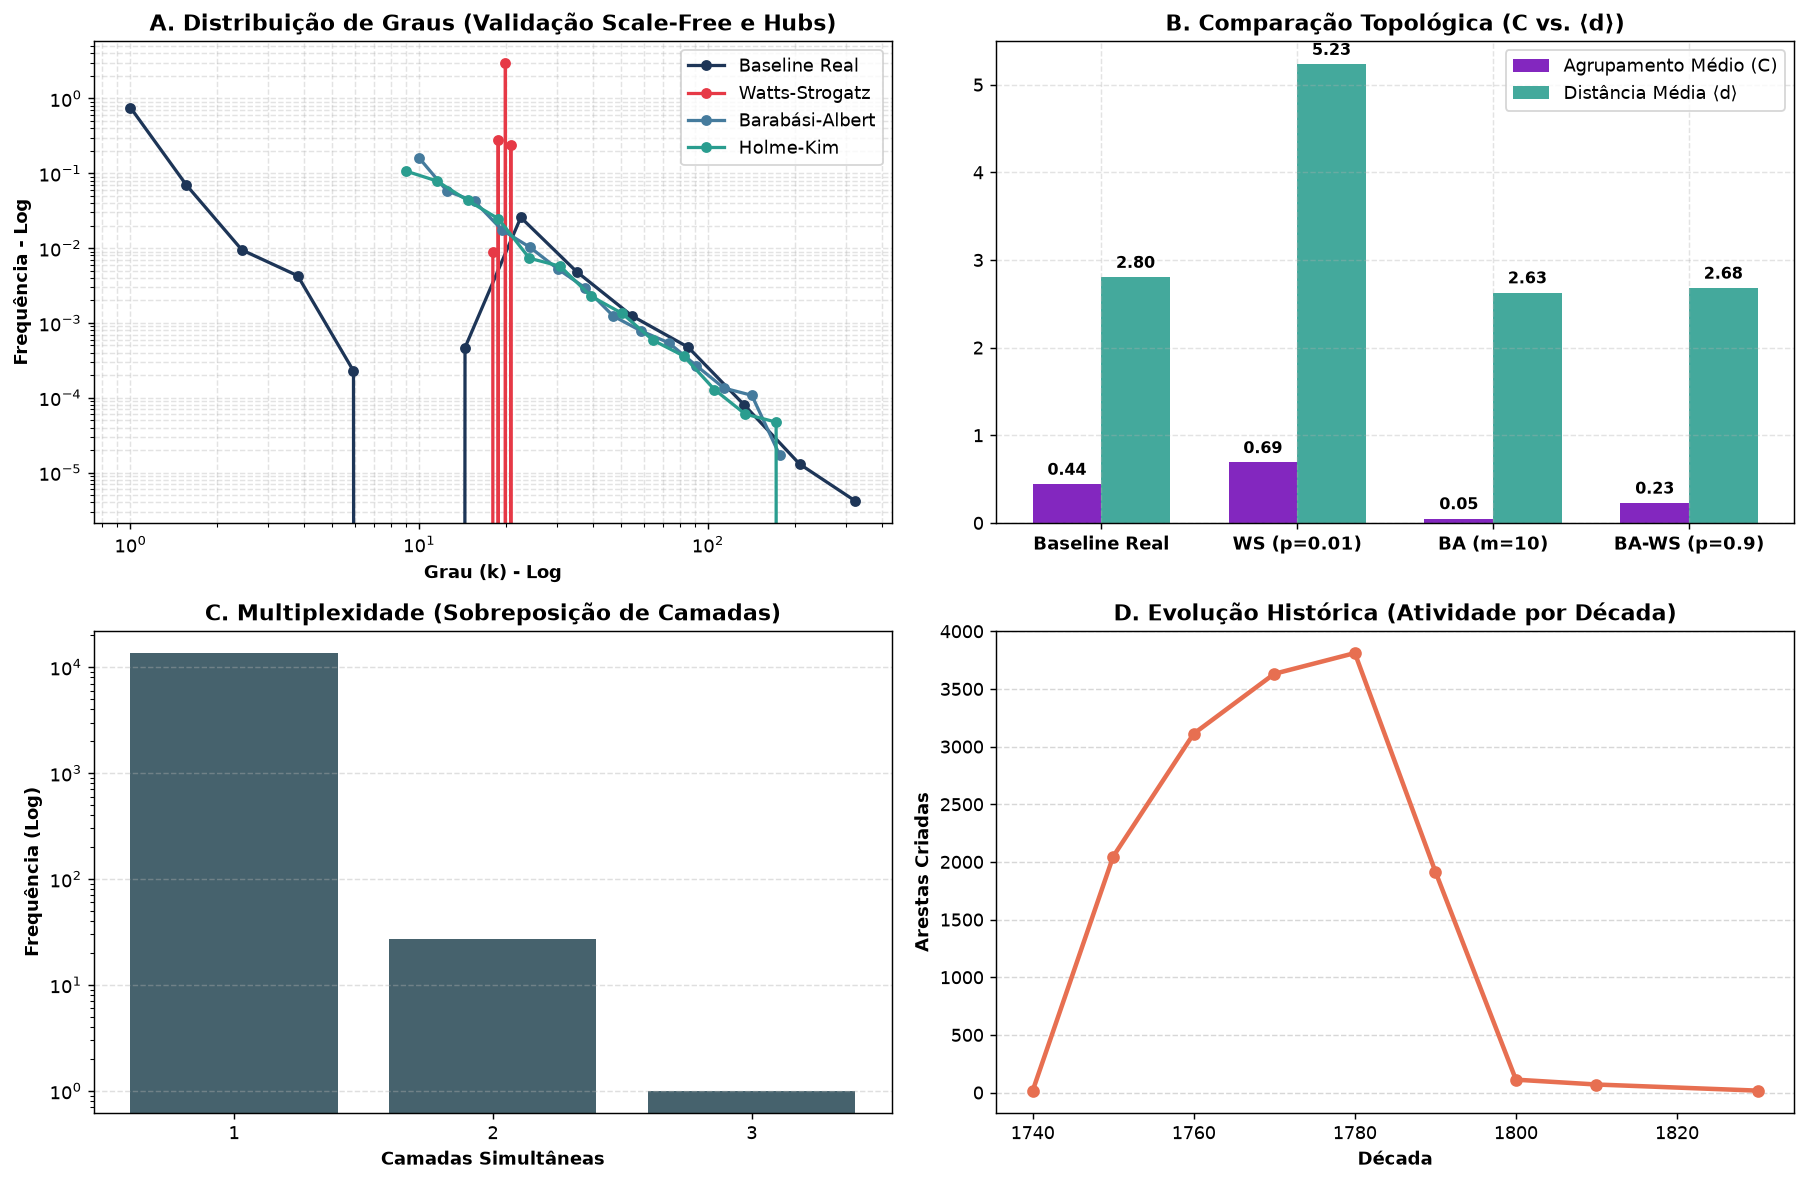

In [5]:
# 5. DIAGNÓSTICOS VISUAIS E COMPARAÇÃO MULTIPLEX/TEMPORAL
# Preparação dos dados para Multiplexidade e Temporalidade
overlap_series = edges_df.groupby(['u', 'v'])[camada_col].nunique()
overlap_dist = overlap_series.value_counts().sort_index()

edges_df['Decada'] = (edges_df[ano_col] // 10) * 10
temporal_dist = edges_df['Decada'].value_counts().sort_index()

# Plot 2x2
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot A: Distribuição de Graus Log-Log
for gr, label, col in [(G, "Baseline Real", "#1D3557"), (G_ws_rep, "Watts-Strogatz", "#E63946"), (G_ba_rep, "Barabási-Albert", "#457B9D"), (G_baws_rep, "Holme-Kim", "#2A9D8F")]:
    degs = [d for n, d in gr.degree()]
    y, x = np.histogram(degs, bins=np.logspace(np.log10(max(1, min(degs))), np.log10(max(degs)), 15), density=True)
    axs[0, 0].plot(x[:-1], y, marker="o", label=label, color=col, linewidth=1.8, markersize=5)

axs[0, 0].set_xscale("log")
axs[0, 0].set_yscale("log")
axs[0, 0].set_title("A. Distribuição de Graus (Validação Scale-Free e Hubs)", fontweight="bold")
axs[0, 0].set_xlabel("Grau (k) - Log", fontweight="bold")
axs[0, 0].set_ylabel("Frequência - Log", fontweight="bold")
axs[0, 0].legend()
axs[0, 0].grid(True, which="both", linestyle="--", alpha=0.35)

# Plot B: Comparação Estrutural
modelos_labels = ["Baseline Real", "WS (p=0.01)", "BA (m=10)", "BA-WS (p=0.9)"]
vals_C = [C_base, np.mean(rep_stats[f"WS (Mundo Pequeno) [k={k_ws}, p=0.01]"]['C_mean']), np.mean(rep_stats[f"BA (Livre de Escala) [m={m_ba}]"]['C_mean']), np.mean(rep_stats[f"BA-WS (Holme-Kim) [m={m_ba}, p=0.9]"]['C_mean'])]
vals_d = [d_base, np.mean(rep_stats[f"WS (Mundo Pequeno) [k={k_ws}, p=0.01]"]['d_mean']), np.mean(rep_stats[f"BA (Livre de Escala) [m={m_ba}]"]['d_mean']), np.mean(rep_stats[f"BA-WS (Holme-Kim) [m={m_ba}, p=0.9]"]['d_mean'])]

x = np.arange(len(modelos_labels))
width = 0.35
bar1 = axs[0, 1].bar(x - width/2, vals_C, width, label="Agrupamento Médio (C)", color="#7209B7", alpha=0.88)
bar2 = axs[0, 1].bar(x + width/2, vals_d, width, label="Distância Média ⟨d⟩", color="#2A9D8F", alpha=0.88)
axs[0, 1].set_xticks(x)
axs[0, 1].set_xticklabels(modelos_labels, fontweight="bold")
axs[0, 1].set_title("B. Comparação Topológica (C vs. ⟨d⟩)", fontweight="bold")
axs[0, 1].legend()
axs[0, 1].grid(True, linestyle="--", alpha=0.35)

for rect in bar1 + bar2:
    height = rect.get_height()
    axs[0, 1].annotate(f"{height:.2f}", xy=(rect.get_x() + rect.get_width()/2, height), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Plot C: Multiplexidade
axs[1, 0].bar(overlap_dist.index, overlap_dist.values, color="#264653", alpha=0.85)
axs[1, 0].set_yscale("log")
axs[1, 0].set_xticks(overlap_dist.index)
axs[1, 0].set_title("C. Multiplexidade (Sobreposição de Camadas)", fontweight="bold")
axs[1, 0].set_xlabel("Camadas Simultâneas", fontweight="bold")
axs[1, 0].set_ylabel("Frequência (Log)", fontweight="bold")
axs[1, 0].grid(axis="y", linestyle="--", alpha=0.4)

# Plot D: Temporalidade
axs[1, 1].plot(temporal_dist.index, temporal_dist.values, marker="o", color="#E76F51", linewidth=2.5)
axs[1, 1].set_title("D. Evolução Histórica (Atividade por Década)", fontweight="bold")
axs[1, 1].set_xlabel("Década", fontweight="bold")
axs[1, 1].set_ylabel("Arestas Criadas", fontweight="bold")
axs[1, 1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


## 6. Conclusão e Seleção do Modelo Teórico Apropriado para o Artigo

### Veredito: O Modelo **Holme-Kim (BA-WS / Power-Law Cluster Graph)** com $p \to 1.0$ é o mais apropriado.

#### Justificativa Científica e Historiográfica:
1. **Inadequação do Modelo Watts-Strogatz (WS)**:
   - Apesar de reproduzir um agrupamento elevado ($C \approx 0,69$), sua distribuição de graus é unimodal em torno de $\langle k \rangle = 21$. O WS **não consegue gerar super-hubs** oligárquicos coloniais, falhando completamente em explicar por que líderes religiosos e militares detêm $k > 150-500$.

2. **Limitação do Modelo Barabási-Albert (BA)**:
   - O modelo BA tradicional captura com precisão o mecanismo de atratividade preferencial (*preferential attachment*) e a cauda pesada de graus, bem como a distância geodésica curta ($\langle d \rangle \approx 2,63$ vs. $2,80$). Porém, seu agrupamento triádico é residual ($C \approx 0,05$), quase 9 vezes inferior ao agrupamento empírico da OTCVR ($C = 0,4424$).

3. **Aderência Superior do Modelo Holme-Kim (BA-WS)**:
   - Ao incorporar um passo de **formação triádica** (*triad formation step*) com probabilidade $p \in [0.9, 1.0]$, o modelo Holme-Kim equilibra simultaneamente a **desigualdade estrutural de poder** (hubs de lei de potência) com a **alta coesão comunitária e transitividade local** ($C = 0,23$ a $0,36$) com $\langle d \rangle \approx 2,68$ a $2,92$.
   - Historiograficamente, isso traduz o arranjo sociopolítico de Vila Rica: um núcleo oligárquico que atrai novas conexões por prestígio institucional (*preferential attachment*), ao mesmo tempo em que os membros desse círculo se co-elegem e se apadrinham continuamente (*triadic closure*).
